# 第5週 AI 分類入門與成果發表

**講師解答版：請勿於練習開始前發給學員。**

每週180分鐘，含10分鐘休息。每個W標號對應PPT與Word同一單元。

教材對照：CH11PPT 11-1至11-3；CH15PPT 15-2概念；CH16PPT 16-1流程。色彩最近中心分類器為本課新增簡化實作

學習目標：
- 能區分規則、訓練與推論
- 能分開訓練資料及保留測試資料
- 能完成分類、評估並解釋限制

先按Shift+Enter逐格執行；交件前重新啟動核心並全部執行。練習格預設以註解保存，請取消註解後完成。請勿將未完成的函數覆蓋示範函數後繼續執行。

## 課前套件
由講師先依總覽安裝套件。核心程式不下載模型或開啟攝影機；色卡由程式自行產生。輸出檔案寫在目前工作目錄的outputs資料夾。

In [1]:
import sys
print("Python", sys.version.split()[0])

Python 3.12.14


## W5-01 AI 概念與本週成果

000–010 分鐘，10分鐘。

- AI 是廣泛領域
- 機器學習從資料估計參數
- 深度學習是機器學習的一支

**操作任務**：說明手寫閾值與從樣本估計平均中心的差別。

**參考答案與驗收**：前者參數由人設定，後者中心由帶標籤訓練資料計算。

## W5-02 特徵與標籤

010–025 分鐘，15分鐘。

- 特徵描述輸入資料
- 標籤是已知類別
- 今日特徵為平均R、G、B

**操作任務**：執行資料準備，印出第一張色卡與特徵，分辨影像、特徵、標籤。

In [2]:
import numpy as np
from PIL import Image
from IPython.display import display
from pathlib import Path
import csv

def make_card(rgb_values):
    image = np.zeros((24, 24, 3), dtype=np.uint8)
    image[:] = rgb_values
    return image

def features(image_rgb):
    return image_rgb.astype(float).mean(axis=(0, 1))

card = make_card([220, 30, 30])
display(Image.fromarray(card))
print(card.shape, features(card))

(24, 24, 3) [220.  30.  30.]


### 練習
先在下方寫出預測，再取消程式註解並完成。

預測：＿＿＿＿

執行後發現：＿＿＿＿

In [3]:
my_card = make_card([30, 220, 30])
assert np.allclose(features(my_card), [30, 220, 30])
print(features(my_card))

[ 30. 220.  30.]


**參考答案與驗收**：影像(24,24,3)；特徵(3,)；標籤為red等類別文字。

## W5-03 訓練集與保留測試集

025–045 分鐘，20分鐘。

- 訓練集用來計算中心
- 測試集保留到模型固定後
- 同張圖片重複放兩邊會洩漏答案

**操作任務**：數出各類訓練與測試筆數，確認沒有相同色卡同時出現在兩側。

In [4]:
train_values = [[220,30,30], [180,20,20], [240,50,50],
                [30,220,30], [20,180,20], [50,240,50],
                [30,30,220], [20,20,180], [50,50,240]]
y_train = np.array(["red"] * 3 + ["green"] * 3 + ["blue"] * 3)
test_values = [[200,25,25], [230,40,40], [25,200,25],
               [40,230,40], [25,25,200], [40,40,230]]
y_test = np.array(["red", "red", "green", "green", "blue", "blue"])
X_train = np.array([features(make_card(v)) for v in train_values])
X_test = np.array([features(make_card(v)) for v in test_values])
print(X_train.shape, X_test.shape)

(9, 3) (6, 3)


### 練習
先在下方寫出預測，再取消程式註解並完成。

預測：＿＿＿＿

執行後發現：＿＿＿＿

In [5]:
assert len(train_values) == 9 and len(test_values) == 6
assert not (set(map(tuple, train_values)) & set(map(tuple, test_values)))
print("沒有完全重複的色卡")

沒有完全重複的色卡


**參考答案與驗收**：每類訓練3筆、測試2筆，共9與6筆。

## W5-04 訓練最近中心分類器

045–060 分鐘，15分鐘。

- 同類特徵取平均
- 中心是從訓練資料算出的參數
- 三個類別各有一個中心

**操作任務**：計算三個中心，手算紅色中心第一個通道與程式核對。

In [6]:
classes = np.unique(y_train)
centroids = []
for label in classes:
    class_rows = X_train[y_train == label]
    centroids.append(class_rows.mean(axis=0))
centroids = np.array(centroids)
for label, center in zip(classes, centroids):
    print(label, np.round(center, 2))

blue [ 33.33  33.33 213.33]
green [ 33.33 213.33  33.33]
red [213.33  33.33  33.33]


### 練習
先在下方寫出預測，再取消程式註解並完成。

預測：＿＿＿＿

執行後發現：＿＿＿＿

In [7]:
manual_red_r = (220 + 180 + 240) / 3
red_index = list(classes).index("red")
assert np.isclose(centroids[red_index, 0], manual_red_r)
print(manual_red_r)

213.33333333333334


**參考答案與驗收**：紅色中心約[213.33,33.33,33.33]，共3個中心。

## W5-05 休息與模型保存

060–070 分鐘，10分鐘。

- 休息10分鐘
- 不要用測試資料重算中心
- 保留資料分組

**操作任務**：存檔與休息。

**參考答案與驗收**：中心只由X_train與y_train計算。

## W5-06 推論與距離

070–090 分鐘，20分鐘。

- 新特徵與各中心比較
- 平方差總和最小者勝出
- 距離不是機率

**操作任務**：預測[200,25,25]，查看三個距離與最小值索引。

In [8]:
def predict_one(feature):
    distances = []
    for center in centroids:
        distances.append(float(np.sum((feature - center) ** 2)))
    index = int(np.argmin(distances))
    return str(classes[index]), distances

prediction, distances = predict_one(X_test[0])
print(prediction, np.round(distances, 2))

red [63316.67 63316.67   316.67]


### 練習
先在下方寫出預測，再取消程式註解並完成。

預測：＿＿＿＿

執行後發現：＿＿＿＿

In [9]:
prediction, _ = predict_one(features(make_card([20, 20, 210])))
assert prediction == "blue"
print(prediction)

blue


**參考答案與驗收**：預測red；最小距離所對應的類別是red。

## W5-07 測試與正確率

090–110 分鐘，20分鐘。

- 每筆預測對照已知標籤
- 正確率是答對筆數除以總筆數
- 小而簡單的測試無法代表所有情況

**操作任務**：列出六筆結果，計算correct、total與accuracy。

In [10]:
predictions = []
for feature in X_test:
    label, _ = predict_one(feature)
    predictions.append(label)
predictions = np.array(predictions)
correct = int(np.sum(predictions == y_test))
accuracy = correct / len(y_test)
for truth, pred in zip(y_test, predictions):
    print("真實", truth, "預測", pred)
print(correct, len(y_test), accuracy)

真實 red 預測 red
真實 red 預測 red
真實 green 預測 green
真實 green 預測 green
真實 blue 預測 blue
真實 blue 預測 blue
6 6 1.0


### 練習
先在下方寫出預測，再取消程式註解並完成。

預測：＿＿＿＿

執行後發現：＿＿＿＿

In [11]:
example_accuracy = 4 / 6
assert np.isclose(example_accuracy, 2 / 3)
print(f"示例正確率 {example_accuracy:.2%}")

示例正確率 66.67%


**參考答案與驗收**：六筆預期皆正確；6/6=1.0，此結果僅適用這組色卡。

## W5-08 陌生樣本與失敗案例

110–125 分鐘，15分鐘。

- 模型只認得既定三類
- 灰色也會被迫選一類
- 同距離時argmin選第一個

**操作任務**：預測[128,128,128]並觀察距離；記錄它應屬未學過的灰色。

In [12]:
unknown = make_card([128, 128, 128])
display(Image.fromarray(unknown))
unknown_label, unknown_distances = predict_one(features(unknown))
print("灰色被分為", unknown_label)
print(np.round(unknown_distances, 2))

灰色被分為 blue
[25205.33 25205.33 25205.33]


### 練習
先在下方寫出預測，再取消程式註解並完成。

預測：＿＿＿＿

執行後發現：＿＿＿＿

In [13]:
yellow_label, yellow_distances = predict_one(features(make_card([230, 230, 20])))
print(yellow_label, np.round(yellow_distances, 2))
print("黃色不在訓練標籤內，輸出不能視為正確辨識黃色")

green [114733.33  39133.33  39133.33]
黃色不在訓練標籤內，輸出不能視為正確辨識黃色


**參考答案與驗收**：距離相同，classes排序第一個為blue；這是平手規則，不是灰色理解。

## W5-09 教材 AI 應用對照

125–140 分鐘，15分鐘。

- 人臉偵測找位置，識別判身分
- 手勢可先估關鍵點再套規則
- 預訓練模型仍需要檢查結果

**操作任務**：將「找出臉框」「認出小安」「紅色卡分類」配對成偵測、識別、分類。

**參考答案與驗收**：找臉框是偵測，認出小安是身分識別，紅色卡是分類。

## W5-10 期末專題與成果發表

140–160 分鐘，20分鐘。

- 保存每筆真實標籤與預測
- 報告6筆保留測試結果
- 展示至少1個失敗或陌生案例

**操作任務**：保存predictions.csv及模型中心；完成3句結論，兩組互講或每組90秒發表。

In [14]:
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)
print("請整理本週成果")

請整理本週成果


### 練習
先在下方寫出預測，再取消程式註解並完成。

預測：＿＿＿＿

執行後發現：＿＿＿＿

In [15]:
with (output_dir / "predictions.csv").open("w", encoding="utf-8-sig", newline="") as file:
    writer = csv.writer(file)
    writer.writerow(["truth", "prediction"])
    writer.writerows(zip(y_test, predictions))
np.savez(output_dir / "color_model.npz", classes=classes, centroids=centroids)
conclusion = f"保留測試{len(y_test)}筆，答對{correct}筆。人工色卡不代表真實物體。灰色未在訓練類別內，仍被迫分類。"
(output_dir / "conclusion.txt").write_text(conclusion, encoding="utf-8")
print(conclusion)

保留測試6筆，答對6筆。人工色卡不代表真實物體。灰色未在訓練類別內，仍被迫分類。


**參考答案與驗收**：CSV有6筆結果；中心以npz保存；結論包含6/6、人工色卡限制、灰色被迫分類。

## W5-11 專題評量與重跑

160–170 分鐘，10分鐘。

- 程式可從乾淨核心重跑
- 資料與方法說明完整
- 限制說明與分數同樣重要

**操作任務**：依總覽評量表互評，提交Notebook、CSV與結論。

**參考答案與驗收**：可重跑且輸出完整；結論沒有將距離稱為機率，也沒有宣稱通用物體辨識。

## W5-12 五週回顧與下一步

170–180 分鐘，10分鐘。

- 變數、控制、函數、資料、影像
- 模型品質需要資料與評估
- 延伸閱讀教材12至16章

**操作任務**：離堂回答：訓練與推論差別、為何分開測試、灰色案例的限制。

**參考答案與驗收**：訓練估計中心，推論使用固定中心；保留測試檢查未用來訓練的資料；模型不能自動拒絕未知類別。

## 課後作業參考解
以下為獨立解答，請在學員完成作業後提供。

In [16]:
print("訓練用資料計算中心；推論以固定中心預測。")
print("保留測試避免用訓練資料冒充未見資料的表現。")
print("灰色不在已知標籤內，分類器仍被迫挑選一類。")

訓練用資料計算中心；推論以固定中心預測。
保留測試避免用訓練資料冒充未見資料的表現。
灰色不在已知標籤內，分類器仍被迫挑選一類。


## 章後習題與詳解補充教材

本段依本週課綱整理，供課後複習與延伸練習，不列入原定180分鐘必做進度。

題目來源：全華《看圖學Python人工智慧程式設計》「中文習題WORD檔(全).doc」。解答來源：「章後習題詳解(全).doc」（文件標示2022/8/1）。保留原章號與題號，逐題配對；原解僅引用課本時保留章節指引。

「原詳解」保留來源內容；「教學補充與勘誤」是本次整理新增。原解中的舊版套件範例須另備教材檔案、相符套件或攝影機；Markdown 內的範例不會隨「全部執行」自動執行。

講師版：每題後直接列出解答，方便講解與核對。

本週章節：第11章、第12章、第13章、第14章、第15章、第16章。



### 第11章：認識人工智慧、機器學習與深度學習

#### 第11章 第1題

請簡單說明什麼人工智慧？

**原詳解**

人工智慧（Artificial Intelligence，AI）也稱為人工智能，這是讓機器變得更聰明的一種科技，也就是讓機器具備和人類一樣的思考邏輯與行為模式。簡單的說，人工智慧就是讓機器展現出人類的智慧，像人類一樣的思考，基本上，人工智慧是一個讓電腦執行人類工作的廣義名詞術語，其衍生的應用和變化至今仍然沒有定論。

人工智慧屬於計算機科學領域的範疇，其發展過程包括學習（大量讀取資訊和判斷何時與如何使用該資訊）、感知、推理（使用已知資訊來做出結論）、自我校正和操縱或移動物品等。



#### 第11章 第2題

請舉例說明什麼是圖靈測試？

**原詳解**

圖靈測試（Turing Test）是計算機科學和人工智慧之父-艾倫圖靈（Alan Turing）在1950年提出，一個定義機器是否擁有智慧的測試，能夠判斷機器是否能夠思考的著名試驗。

圖靈測試提出了人工智慧的概念，讓我們相信機器是有可能具備智慧的能力，簡單的說，圖靈測試是在測試機器是否能夠表現出與人類相同或無法區分的智慧表現，如下圖所示：

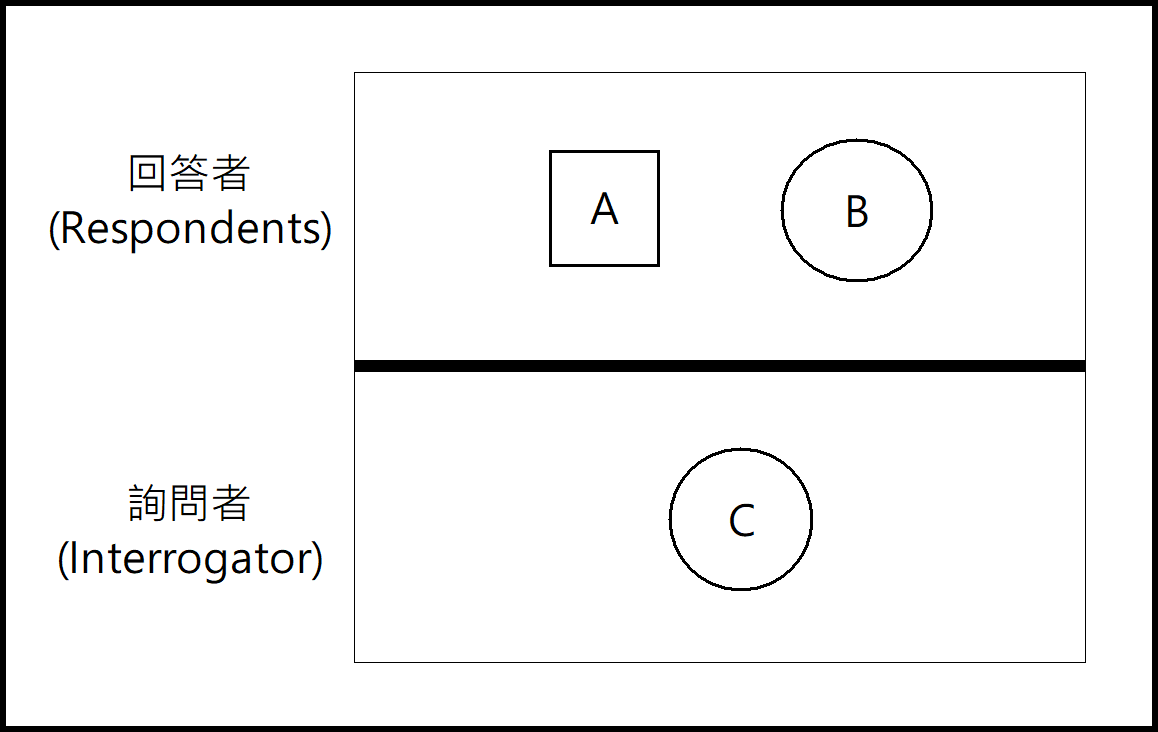

上述正方形A代表一台機器，圓形B代表人類，這兩位是回答者（Respondents），人類C是一位詢問者（Interrogator），展開與A和B的對話，對話是透過文字模式的鍵盤輸入和螢幕輸出來進行，如果A不會被辨別出是一台機器的身份，就表示這台機器A具有智慧。



#### 第11章 第3題

請問人工智慧的應用領域有哪些？

**原詳解**

請參閱第11-1-2節的說明。



#### 第11章 第4題

請簡單說明什麼是機器學習？機器學習可以解決的問題有哪些？

**原詳解**

請參閱第11-2-1節和11-2-2節的說明。



#### 第11章 第5題

請問機器學習的種類有哪些？

**原詳解**

請參閱第11-2-3節的說明。



#### 第11章 第6題

請簡單說明什麼是深度學習？

**原詳解**

請參閱第11-3節的說明。



### 第12章：人工智慧應用（一）：人臉偵測與人臉識別

#### 第12章 第1題（延伸練習）

請問什麼是MediaPipe？CVZone套件的用途？

**原詳解**

MediaPipe是 Google公司開發的機器學習框架，這是跨平台的機器學習解決方案，可以讓AI研究者和開發者建立世界等級，針對手機、PC、雲端、Web和IoT裝置的機器學習應用程式和解決方案。

MediaPipe跨平台支援Android、iOS、Web和邊緣運算裝置，C++、JavaScript和Python程式語言，隨著平台釋出的相關應用範例，可以讓我們馬上執行人工智慧應用，包含：人臉偵測（Face Detection）、多手勢追蹤（Multi-hand Tracking）和人體姿態評估（Human Pose Estimation）等。

CVZone是基於OpenCV和MediaPipe的Python電腦視學套件，可以讓我們使用更少的程式碼，和以更容易的方式來輕鬆進行人臉偵測、3D臉部網格、多手勢追蹤和人體姿態評估等電腦視學應用。



#### 第12章 第2題（延伸練習）

請簡單說明人臉偵測和人臉識別的差異？

**原詳解**

人臉偵測和人臉識別的差異，如下所示：

人臉偵測（Face Detection）：偵測影像或影格中是否有人臉。

人臉識別（Face Recognition）：不只偵測出人臉，還需判斷這張臉是誰？



#### 第12章 第3題（延伸練習）

請一一列出face-recognition套件的功能？如何在Windows電腦的Python開發環境安裝此套件？

**原詳解**

請參閱第12-5節的說明。



#### 第12章 第4題（延伸練習）

請建立Python程式開啟Webcam，可以計算目前影格中有多少人，並且顯示在影格左上角（提示：即偵測出的人臉數）。

**原詳解**

請參考整合ch12-2-3.py和ch12-2-1b.py來修改。



#### 第12章 第5題（延伸練習）

請建立Python程式判斷臉部表情的右眼是張開或閉著。

**原詳解**

請參考ch12-4a.py來修改。



#### 第12章 第6題（延伸練習）

請找出你自己的3張大頭貼照片，然後建立Python程式產生這3張照片的臉部資料編碼，然後計算出哪兩張照片的差異最小。

**原詳解**

請參考ch12-5-2c.py來修改。



### 第13章：人工智慧應用（二）：多手勢追蹤與人體姿態評估

#### 第13章 第1題（延伸練習）

CVZone多手勢追蹤可以偵測出手部____個關鍵點。CVZone人體姿態評估可以偵測出人體姿勢的______個關鍵點。

**原詳解**

21、33



#### 第13章 第2題（延伸練習）

請問CVZone多手勢追蹤是如何知道伸出哪幾根手指，需要如何計算伸出的總手指數？

**原詳解**

```text
在Python程式可以使用HandDetector物件的fingersUp()方法，偵測出手掌伸出了哪幾根手指，如下所示：
fingers = detector.fingersUp(hand)
上述方法的回傳值是5根手指（從姆指開始至小指）的串列，例如：[0, 1, 1, 0, 0]，值1是伸出；0沒有，以此例是伸出食指和中指。
然後使用fingers.count(1)方法計算值1出現的數量，即共伸出幾根手指。
```



#### 第13章 第3題（延伸練習）

請參考第13-2節的Python程式範例，使用CVZone辨識出剪刀手勢後，再判斷剪刀的2根手指是合起或張開。

**原詳解**

請參考ch13-2.py來修改，使用2根手指的距離來判斷。



#### 第13章 第4題（延伸練習）

在第13-2節的Python程式偵測「布」手勢是因為伸出5根手指，問題是並沒有判斷手指之間是否有展開，請進一步判斷各手指之間需要超過多少距離，才是真正的「布」手勢。

**原詳解**

請參考ch13-2.py來修改，加上計算出各手指之間的距離來判斷。



#### 第13章 第5題（延伸練習）

深蹲姿勢有2個狀態：站起和蹲下，請建立Python程式判斷人體姿態是「站起」或「蹲下」（提示：判斷腳部膝蓋的角度）。

**原詳解**

請參考ch14-2-3.py。



#### 第13章 第6題（延伸練習）

請整合Python程式ch13-5.py和Webcam，可以即時標示影格目前的姿勢是「仰臥」或「起坐」。

**原詳解**

請參考ch14-2-1.py。



### 第14章：AI整合實戰（一）：手勢操控、健身教練與刷臉簽到

#### 第14章 第1題（延伸練習）

請建立一個全新的Python程式AI健身教練，這是單槓訓練的引體向上，可以在影格顯示目前已經做了幾次引體向上（請自行在Youtube搜尋可用的視訊）。

**原詳解**

```text
import cv2
import numpy as np
from PoseModule import PoseDetector

cap = cv2.VideoCapture("Pull_up_clip.mp4")
detector = PoseDetector()
dir = 0
count = 0
while True:
    success, img = cap.read()
    if success:
        img = cv2.resize(img, (640, 480))
        pose, img = detector.findPose(img, draw=True)
        if pose:
            lmList = pose["lmList"]
            right_angle, img = detector.findAngle(lmList[12], lmList[14], lmList[16], img)
            right_per = np.interp(right_angle, (20, 170), (100, 0))
            right_bar = np.interp(right_angle, (20, 170), (200, 400))
            cv2.rectangle(img, (500, 200), (520, 400), (0, 255, 0), 3)
            cv2.rectangle(img, (500, int(right_bar)), (520, 400), (0, 255, 0), cv2.FILLED)
            cv2.putText(img, str(int(right_per)) + '%', (490, 450), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 255), 2)
            left_angle, img = detector.findAngle(lmList[11], lmList[13], lmList[15], img)
            left_per = np.interp(left_angle, (20, 170), (100, 0))
            left_bar = np.interp(left_angle, (20, 170), (200, 400))
            cv2.rectangle(img, (100, 200), (120, 400), (0, 255, 0), 3)
            cv2.rectangle(img, (100, int(left_bar)), (120, 400), (0, 255, 0), cv2.FILLED)
            cv2.putText(img, str(int(left_per)) + '%', (90, 450), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 255), 2)
            print(int(left_per), int(right_per))
            if (left_per >= 80 and right_per >= 80):
                if dir == 0:
                    count = count + 0.5
                    dir = 1
            if (left_per <= 50 and right_per <= 50):
                if dir == 1:
                    count = count + 0.5
                    dir = 0

            cv2.putText(img, str(int(count)), (100, 100), cv2.FONT_HERSHEY_SIMPLEX, 3, (0, 255, 255), 4)
        cv2.imshow('Image', img)
    else:
        break
    k = cv2.waitKey(1)
    if k == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()
```



#### 第14章 第2題（延伸練習）

請整合第14-3節和第9-5-3 節的Excel軟體自動化，可以自動將簽到資料記錄至Excel試算表的儲存格。

**原詳解**

請參考整合ch9-5-3a.py、ch14-3a.py來修改。



### 第15章：人工智慧應用（三）：影像分類、物體識別與OCR文字識別

#### 第15章 第1題

請問什麼是OpenCV DNN模組？何謂預訓練模型？

**原詳解**

請參閱第15-1-1節的說明。

預訓練模型（Pre-trained Models）就是使用Caffe、TensorFlow、Torch/Pytorch和Darknet等框架已經成功完成訓練的深度學習模型，除了模型結構，還包含訓練結果的權重檔。



#### 第15章 第2題

請簡單說明什麼是TensorFlow和TensorFlow Lite？

**原詳解**

請參閱第15-1-2節的說明。



#### 第15章 第3題

請簡單說明影像分類、物體識別和文字偵測是什麼？何謂EAST？

**原詳解**

影像分類（Image Classification）就是讓電腦能夠分析影像內容是屬於哪一類影像，正確的說，最有可能是哪一類影像，例如：提供一張無尾熊影像，影像分類可以讓電腦分析影像，告訴我是一隻無尾熊。

物體識別（Object Recognition）是一種可以在影像的數位內容中，同時辨識出多種物體的電腦視覺應用領域，例如：在影像中辨識出人、車輛、椅子、石頭、建築物和各種動物等。事實上，物體識別就是在回答下列2個基本問題，如下所示：

這是什麼東西？

這個東西在哪裡？

文字偵測就是在影像的數位內容中偵測出包含的文字內容。EAST（An Efficient and Accurate Scene Text Detector）是一種高效且正確率高的文字偵測預訓練模型，在這一節我們準備使用OpenCV DNN模組來建立EAST文字偵測。



#### 第15章 第4題（延伸練習）

請問Tesseract-OCR是什麼？Python程式如何使用Tesseract-OCR？

**原詳解**

OCR是Optical Character Recognition光學字元識別的縮寫，可以自動識別出影像中的文字將它轉換成字串。Tesseract-OCR引擎最早是HP實驗室在1985年開發，目前Tesseract已經是Google開源項目，提供一個命令列工具來執行OCR操作，讓我們從影像識別出之中的文字。

請參閱第15-5-2節的說明。



#### 第15章 第5題（延伸練習）

請整合Python程式ch15-2-1.py和Webcam，可以建立OpenCV DNN模組的即時影像分類，在視訊的影格中分類影像。

**原詳解**

請參考整合ch10-3-2.py、ch15-2-1.py來修改。



#### 第15章 第6題（延伸練習）

請整合Python程式ch15-2-2.py和Webcam，可以建立TensorFlow Lite的即時影像分類，在視訊的影格中分類影像。

**原詳解**

請參考整合ch10-3-2.py、ch15-2-2.py來修改。



#### 第15章 第7題（延伸練習）

請整合Python程式ch15-4.py和Webcam，可以建立OpenCV DNN模組的即時文字偵測，在視訊的影格中標示出偵測到的文字區域。

**原詳解**

請參考整合ch10-3-2.py、ch15-4.py來修改。



#### 第15章 第8題（延伸練習）

請從網路找出更多包含文字內容的影像檔，首先參考第15-4節建立Python程式執行文字偵測，然後切割出文字區域的影像後，將切割影像使用Tesseract-OCR轉換成文字內容和顯示出來。

**原詳解**

請參考ch16-2-1.py來修改。



### 第16章：AI整合實戰（二）：Teachable Machine訓練模型與車牌辨識

#### 第16章 第1題（延伸練習）

請試著從手邊找出 3 種不同的物體，然後使用第 16-1-1 節的 Teachable Machine 訓練出可分類這些物體影像的模型。

**原詳解**

請參閱第16-1-1節的說明與步驟。



#### 第16章 第2題（延伸練習）

請參考第 16-1-2 節的 Python 程式，改用學習評量 1. 訓練的模型來分類影像。

**原詳解**

請參考ch16-1-2.py來修改。



#### 第16章 第3題（延伸練習）

請從網路尋找一些含車牌的車輛影像檔，然後調整第 16-2-1 節的 Python 程式來正確的執行車牌辨識（除了使用面積判斷是車牌外，還可以使用長寬比例來判斷文字區域是車牌）。

**原詳解**

```text
請參考ch16-2-1.py來修改。長寬比例即寬w是高h的兩倍來判斷文字區域是車牌，如下所示：
if w > 2 * h:        
    print("Detect Car License Plate!")
```

**教學補充與勘誤**

原解 w>2*h 僅能作為車牌候選區域的啟發式篩選，不能保證是車牌；仍需配合面積、位置及文字識別結果判斷。



#### 第16章 第4題（延伸練習）

請繼續學習評量 3.，改用 EasyOCR 來執行車牌辨識。

**原詳解**

請參考ch16-2-3.py來修改。



### Copilot 輔助學習

先自行作答，再請 Copilot 解釋程式、提出邊界測試並與本段原詳解及勘誤比對。以下提示詞是教材內容，供學員自行複製使用。

#### 本週延伸提示詞（本次新增）

提供的 Copilot 資料夾僅有第1至9章，以下為配合本週主題新增的提示詞。

```text
請比較規則判斷、機器學習與深度學習，並以本週色彩分類器說明訓練集、測試集與資料洩漏。請先給提示，待我作答後再逐項檢查理由。
```